# House Prices - XGBoost voi tung cap dac trung tong hop

Them tung cap cot vao 79 cot goc. So sanh RMSE log tren cung 5 fold va giu nguyen sieu tham so.

## Tham số cố định

In [1]:
EXPERIMENT_NAME = "15-11-2026_XGBoost_cap_dac_trung_phuc"
RANDOM_STATE = 42
N_SPLITS = 5
MODEL_PARAMS = {
    "n_estimators": 200, "max_depth": 4, "learning_rate": 0.05,
    "random_state": RANDOM_STATE, "n_jobs": 2,
}

## Import và kiểm tra kernel

In [2]:
from itertools import combinations
import json
import sys
import warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline

cwd = Path.cwd().resolve()
project = next(
    path for path in (cwd, *cwd.parents, cwd / "Challenge1_House Prices_ Advanced Regression")
    if (path / "src" / "prepare_data.py").is_file()
    and (path / "data" / "raw" / "train.csv").is_file()
)
sys.path.insert(0, str(project))

try:
    import xgboost
except ModuleNotFoundError as error:
    if error.name != "xgboost":
        raise
    raise ModuleNotFoundError(
        "Kernel chua co XGBoost. Chay %pip install xgboost-cpu roi Restart Kernel."
    ) from error

from src.model import make_xgboost
from src.prepare_data import DATA_DIR, ID, TARGET, extract_features, make_preprocessor

## Dữ liệu và tạo đặc trưng

- `TotalSF` cộng diện tích tầng hầm, tầng 1 và tầng 2.
- `TotalBath` cộng phòng tắm đầy đủ ở phần trên mặt đất và tầng hầm. Mỗi nửa phòng tắm tính 0,5.
- `AgeAtSale` lấy năm bán trừ năm xây.

Các phép tính dùng dữ liệu của từng căn nhà. Pipeline điền thiếu, chuẩn hóa và mã hóa được fit trên phần train của từng fold.

In [3]:
train = pd.read_csv(DATA_DIR / "raw" / "train.csv")
X = extract_features(train)
prices = train[TARGET]
assert X.shape[1] == 79
assert np.isfinite(prices).all() and prices.gt(0).all()
y = np.log(prices)

formulas = {
    "TotalSF": "TotalBsmtSF + 1stFlrSF + 2ndFlrSF",
    "TotalBath": "FullBath + BsmtFullBath + 0.5 * (HalfBath + BsmtHalfBath)",
    "AgeAtSale": "YrSold - YearBuilt",
}
X_extra = X.assign(
    TotalSF=X["TotalBsmtSF"] + X["1stFlrSF"] + X["2ndFlrSF"],
    TotalBath=X["FullBath"] + X["BsmtFullBath"] + 0.5 * (X["HalfBath"] + X["BsmtHalfBath"]),
    AgeAtSale=X["YrSold"] - X["YearBuilt"],
)
assert X_extra.shape[1] == 82
display(X_extra[list(formulas)].describe().round(2))

cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
splits = list(cv.split(X))
predictions = pd.DataFrame({ID: train[ID], "ln_SalePrice": y, "fold": 0})
for fold, (_, valid_idx) in enumerate(splits, 1):
    predictions.loc[valid_idx, "fold"] = fold
baseline_dir = (project / "experiments" / "14-11-2026_6model_79_phuc"
                / "outputs" / "20261114_224507_500186")
baseline = pd.read_csv(baseline_dir / "validation_predictions.csv")
assert predictions[[ID, "fold"]].equals(baseline[[ID, "fold"]])
np.testing.assert_allclose(y, baseline["ln_SalePrice"])

,TotalSF,TotalBath,AgeAtSale
count,1460.00,1460.00,1460.00
mean,2567.05,2.21,36.55
std,821.71,0.79,30.25
min,334.00,1.00,0.00
25%,2009.50,2.00,8.00
50%,2474.00,2.00,35.00
75%,3004.00,2.50,54.00
max,11752.00,6.00,136.00


## Huấn luyện và so sánh

In [4]:
metric_rows = []
warning_rows = []
fold_columns = [f"fold{i}" for i in range(1, N_SPLITS + 1)]
variants = {"79_goc": X}
feature_pairs = list(combinations(formulas, 2))
for pair in feature_pairs:
    variants[" + ".join(pair)] = X_extra.loc[:, [*X.columns, *pair]]
variants["82_ca_ba"] = X_extra

for name, features in variants.items():
    pipeline = make_pipeline(make_preprocessor(features), make_xgboost(**MODEL_PARAMS))
    scores = []
    started = perf_counter()
    for fold, (fit_idx, valid_idx) in enumerate(splits, 1):
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fitted = clone(pipeline).fit(features.iloc[fit_idx], y.iloc[fit_idx])
            predicted = fitted.predict(features.iloc[valid_idx])
        predictions.loc[valid_idx, f"xgboost_{name}"] = predicted
        scores.append(root_mean_squared_error(y.iloc[valid_idx], predicted))
        for item in caught:
            warning_rows.append({"features": name, "fold": fold,
                                 "category": item.category.__name__, "message": str(item.message)})
    metric_rows.append({
        "model": "XGBoost", "variant": name, "features": features.shape[1],
        **dict(zip(fold_columns, scores)),
        "rmse_log_mean": np.mean(scores), "rmse_log_std": np.std(scores, ddof=1),
        "elapsed_seconds": perf_counter() - started,
    })

assert predictions[[f"xgboost_{name}" for name in variants]].notna().all().all()
results = pd.DataFrame(metric_rows).set_index("variant")
comparison = results[fold_columns].subtract(results.loc["79_goc", fold_columns], axis="columns")
comparison["delta_mean"] = results["rmse_log_mean"] - results.loc["79_goc", "rmse_log_mean"]
comparison["folds_improved"] = (comparison[fold_columns] < 0).sum(axis=1)
display(results.round(5))
display(comparison.round(5))

,model,features,fold1,fold2,fold3,fold4,fold5,rmse_log_mean,rmse_log_std,elapsed_seconds
variant,,,,,,,,,,
79_goc,XGBoost,79,0.13278,0.11839,0.16912,0.13413,0.11311,0.13351,0.02187,1.39930
TotalSF + TotalBath,XGBoost,81,0.13941,0.12002,0.16284,0.12824,0.11645,0.13339,0.01868,1.41366
TotalSF + AgeAtSale,XGBoost,81,0.13881,0.11714,0.16767,0.12695,0.11217,0.13255,0.02212,1.42120
TotalBath + AgeAtSale,XGBoost,81,0.13379,0.11873,0.16756,0.13078,0.11645,0.13346,0.02047,1.47100
82_ca_ba,XGBoost,82,0.13851,0.11829,0.16862,0.12793,0.11756,0.13418,0.02105,1.41257


,fold1,fold2,fold3,fold4,fold5,delta_mean,folds_improved
variant,,,,,,,
79_goc,0.0,0.0,0.0,0.0,0.0,0.00000,0
TotalSF + TotalBath,0.006626,0.001628,-0.006276,-0.005882,0.003342,-0.00011,2
TotalSF + AgeAtSale,0.006027,-0.001252,-0.001446,-0.007178,-0.000946,-0.00096,4
TotalBath + AgeAtSale,0.001014,0.000341,-0.001561,-0.003347,0.003339,-0.00004,2
82_ca_ba,0.00573,-0.0001,-0.000495,-0.006193,0.00445,0.00068,3


## Biểu đồ và nhận xét

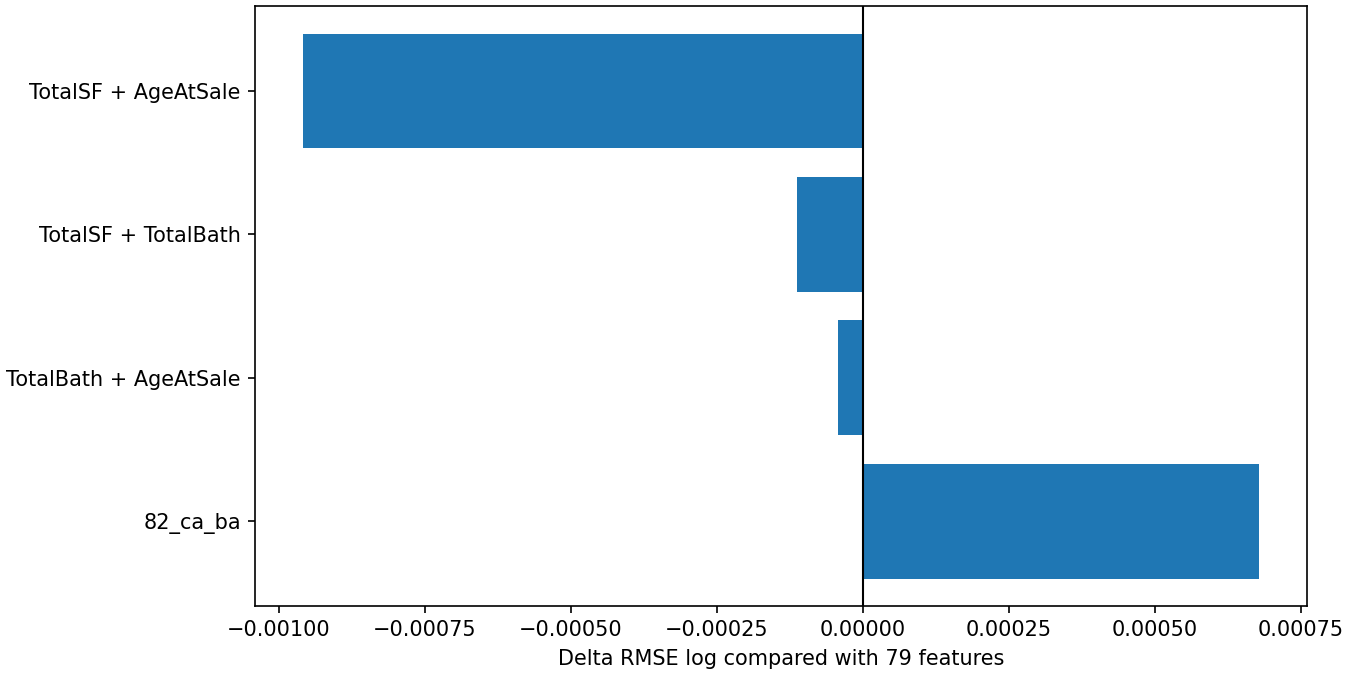

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
deltas = comparison.drop(index="79_goc")["delta_mean"].sort_values()
ax.barh(deltas.index, deltas)
ax.axvline(0, color="black", linewidth=1)
ax.set(xlabel="Delta RMSE log compared with 79 features", ylabel="")
ax.invert_yaxis()
plt.show()

## Lưu kết quả

In [6]:
run_time = datetime.now(timezone(timedelta(hours=7)))
run_dir = project / "experiments" / EXPERIMENT_NAME / "outputs" / run_time.strftime("%Y%m%d_%H%M%S_%f")
image_dir = run_dir / "img"
image_dir.mkdir(parents=True, exist_ok=False)
results.to_csv(run_dir / "validation_metrics.csv")
comparison.to_csv(run_dir / "comparison_by_pair.csv", index_label="variant")
predictions.to_csv(run_dir / "validation_predictions.csv", index=False)
pd.DataFrame(warning_rows, columns=["features", "fold", "category", "message"]).to_csv(
    run_dir / "validation_warnings.csv", index=False
)
config = {
    "dataset": "data/raw/train.csv", "target_transform": "natural log",
    "baseline": str(baseline_dir.relative_to(project)), "feature_formulas": formulas, "feature_pairs": feature_pairs,
    "cv": {"n_splits": N_SPLITS, "shuffle": True, "random_state": RANDOM_STATE},
    "model_params": MODEL_PARAMS, "xgboost_version": xgboost.__version__,
}
(run_dir / "manual_params.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
fig.savefig(image_dir / "xgboost_by_pair.png", dpi=150)
print(run_dir.relative_to(project))

experiments\15-11-2026_XGBoost_cap_dac_trung_phuc\outputs\20261115_094428_793379
